# Construção e treinamento de modelo de ML para classificação de espécies de flores Irís


* caracteristicas:
* comprimento e largura de sépalase pétalas



In [ ]:
#====================================================
# Passo 1 - Importante biliotecas e carregando dados
#====================================================
#Importando bibliotecas
import tensorflow as tf
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Carregando conjunto de dados Irís
iris = load_iris()
X = iris.data
y = iris.target

In [ ]:
#======================================
#Passo 2 - Pré processamento dos dados
#======================================

# Dividindo os dados em conjuntos de treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Inicializando o padronizador (StandardScaler)
scaler = StandardScaler()

# Ajustando o padronizador e transformando os dados de treino
X_train_scaled = scaler.fit_transform(X_train)

# Aplicando a mesma transformação nos dados de teste
X_test_scaled = scaler.transform(X_test)

# Exibindo o formato dos dados para validação
print(f"Treino: {X_train_scaled.shape}, Teste: {X_test_scaled.shape}")

Treino: (120, 4), Teste: (30, 4)


In [ ]:
#======================================
# Passo 3 - Construindo o modelo
#======================================

# Definindo a arquitetura do modelo sequencial
model = tf.keras.Sequential([
    # Camada de entrada que recebe as 4 características (comprimento/largura de sépala/pétala)
    tf.keras.layers.Input(shape=(4,)),

    # Camada oculta densa com 16 neurônios e função de ativação ReLU
    tf.keras.layers.Dense(16, activation='relu'),

    # Outra camada oculta opcional com 8 neurônios para melhorar o aprendizado
    tf.keras.layers.Dense(8, activation='relu'),

    # Camada de saída com 3 neurônios (um para cada classe do Iris) e ativação Softmax para probabilidades
    tf.keras.layers.Dense(3, activation='softmax')
])

# Compilando o modelo
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # Usado quando os alvos (y) são números inteiros (0, 1, 2)
    metrics=['accuracy']                     # Métrica de avaliação de desempenho
)

# 3. Exibindo o resumo da estrutura do modelo criado
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#======================================
# Passo 4 - Treinando o modelo
#======================================

# Treinando a rede neural e guardando as métricas no histórico
history = model.fit(
    X_train_scaled,          # Atributos de treino normalizados
    y_train,                 # Rótulos (classes) de treino
    epochs=50,               # Número de vezes que a rede verá todo o conjunto de dados
    batch_size=8,            # Tamanho dos lotes de dados processados antes de atualizar os pesos
    validation_split=0.1,    # Separa 10% do treino para validação durante o treinamento
    verbose=1                # Exibe o progresso de cada época na tela
)

Epoch 1/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.2500 - loss: 1.1776 - val_accuracy: 0.1667 - val_loss: 1.1829
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3148 - loss: 1.1020 - val_accuracy: 0.4167 - val_loss: 1.0897
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5185 - loss: 1.0335 - val_accuracy: 0.5000 - val_loss: 1.0045
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6389 - loss: 0.9710 - val_accuracy: 0.6667 - val_loss: 0.9120
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7315 - loss: 0.9096 - val_accuracy: 0.6667 - val_loss: 0.8353
Epoch 6/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7870 - loss: 0.8469 - val_accuracy: 0.6667 - val_loss: 0.7720
Epoch 7/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8148 - loss: 0.7899 - val_accuracy: 0.6667 - val_loss: 0.7110
Epoch 8/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8241 - loss: 0.7381 - val_accuracy: 0.6667 - val_los

In [ ]:
#=================================================
# Passo 5 - Avaliando o modelo com dados de teste
#=================================================

# Avaliando o desempenho do modelo no conjunto de teste
loss, accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)

# Exibindo os resultados obtidos
print("=== Avaliação no Conjunto de Teste ===")
print(f"Perda (Loss): {loss:.4f}")
print(f"Acurácia (Accuracy): {accuracy * 100:.2f}%")

=== Avaliação no Conjunto de Teste ===
Perda (Loss): 0.2091
Acurácia (Accuracy): 90.00%


In [ ]:
#=============================================
# Passo 6 - Fazendo previsões com novos dados
#=============================================
import numpy as np

# Definindo dados de uma nova flor (exemplo: comprimento/largura de sépala e pétala)
# Formato: [sepal_length, sepal_width, petal_length, petal_width]
nova_flor = np.array([[5.1, 3.5, 1.4, 0.2]])

# Normalizar os novos dados usando o scaler ajustado anteriormente
nova_flor_scaled = scaler.transform(nova_flor)

# Realizar a previsão utilizando o modelo treinado
previsao = model.predict(nova_flor_scaled)

# Obter a classe com maior probabilidade
classe_predita = np.argmax(previsao)
nome_classe = iris.target_names[classe_predita]

# Exibindo os resultados
print("=== Resultado da Predição ===")
print(f"Dados de entrada: {nova_flor[0]}")
print(f"Probabilidades por classe: {previsao[0]}")
print(f"Espécie classificada: {nome_classe.upper()} (Classe {classe_predita})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
=== Resultado da Predição ===
Dados de entrada: [5.1 3.5 1.4 0.2]
Probabilidades por classe: [9.9892032e-01 1.8229609e-04 8.9741609e-04]
Espécie classificada: SETOSA (Classe 0)


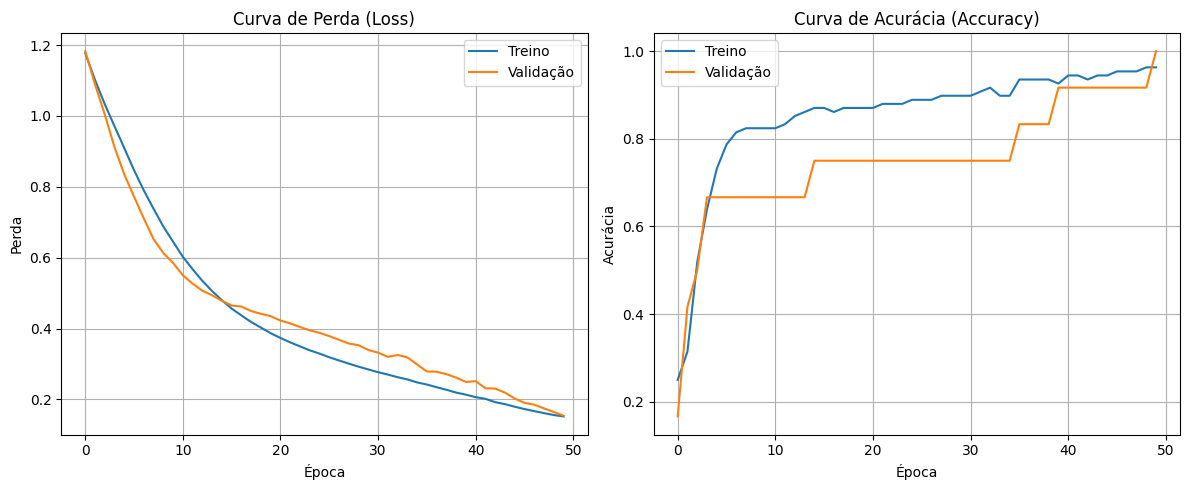

In [ ]:
import matplotlib.pyplot as plt

# Criando uma figura para os gráficos
plt.figure(figsize=(12, 5))

# Gráfico de Perda (Loss)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Treino')
plt.plot(history.history['val_loss'], label='Validação')
plt.title('Curva de Perda (Loss)')
plt.xlabel('Época')
plt.ylabel('Perda')
plt.legend()
plt.grid(True)

# Gráfico de Acurácia (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Treino')
plt.plot(history.history['val_accuracy'], label='Validação')
plt.title('Curva de Acurácia (Accuracy)')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)

# Exibindo os gráficos
plt.tight_layout()
plt.show()

## 🧠 Conclusões e aprendizados

O desenvolvimento deste projeto permitiu explorar as principais etapas de criação de um modelo de Machine Learning para classificação de flores, desde a preparação e padronização dos dados até o treinamento, a avaliação e a realização de previsões com novos exemplos.

### 📊 Avaliação do modelo

O modelo apresentou **90% de acurácia no conjunto de teste**, classificando corretamente 27 das 30 flores que não haviam sido utilizadas durante o treinamento. Esse resultado demonstra que o modelo conseguiu identificar padrões relevantes nos dados para realizar as classificações.

A perda obtida foi de **0,2244**, valor próximo ao observado na validação, indicando consistência entre os resultados dessas etapas de avaliação.

### 🌸 Previsão com novos dados

Também foi implementado um exemplo prático de previsão utilizando as características de uma flor fictícia. Após a padronização dos dados, o modelo calculou as seguintes probabilidades para cada classe:

- **Setosa (Classe 0):** 99,28%
- **Versicolor (Classe 1):** 0,22%
- **Virginica (Classe 2):** 0,49%

A maior probabilidade foi atribuída à classe Setosa, indicando que essa foi a classificação prevista pelo modelo para o exemplo utilizado.

### 💡 O que aprendi

Com esta atividade, aprofundei meus conhecimentos em Python e nos fundamentos de Machine Learning, especialmente na preparação de dados, padronização de variáveis, treinamento de modelos de classificação e interpretação de métricas de avaliação.

O projeto também ajudou a compreender a importância de testar o modelo com dados não utilizados no treinamento e de analisar suas previsões para avaliar seu comportamento em situações práticas.

Como próximo passo, pretendo continuar estudando técnicas de avaliação e aprimoramento de modelos, ampliando meus conhecimentos em análise de dados e aprendizado de máquina.